# Customer Churn / Sales Trend Analysis
**Project 03 | Data Science & AI | InternCircle**

**Goal:** Analyse an e-commerce sales dataset to find revenue trends, the best product categories and the most valuable customers, then recommend actions a business can take.

**Tools:** Python, pandas, numpy, matplotlib, seaborn

> **Data note:** This project uses a **generated (simulated) dataset**, not real customer data. No real customers are involved. Because the data is simulated, the patterns are for practising the method, and a real business would need to confirm them with its own data.

---
## 1. The Business Question
A manager wants to know:
1. **Which months and categories earn the most?**
2. **Who are our best customers, and does the 80/20 rule hold?**
3. **Which customers may be leaving (churn)?**
4. **What should we do next?**

## 2. Assumptions
- One year of orders (1 Jan to 31 Dec 2025), 2,000 orders from 300 customers, in 4 categories.
- `amount` is the order value in USD (simulated).
- A customer is treated as **inactive / at risk of churn** if they placed no order in the last **90 days** of the data (after 2 Oct 2025). This 90-day rule is my own assumption.
- Month-to-month changes in simulated data are partly random, so I describe patterns carefully and do not claim causes.

## 3. Create the Data and Check It

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

sns.set_theme(style="whitegrid")
BLUE, ORANGE = "#0072B2", "#E69F00"   # colour-blind-friendly palette

# Practice dataset generator (seed fixed so results are repeatable)
rng = np.random.default_rng(42)
n = 2000
orders = pd.DataFrame({
    "order_date": pd.to_datetime("2025-01-01") + pd.to_timedelta(rng.integers(0, 365, n), unit="D"),
    "customer_id": rng.integers(1, 301, n),
    "category": rng.choice(["Electronics", "Fashion", "Home", "Books"], n, p=[0.3, 0.35, 0.2, 0.15]),
    "amount": rng.gamma(2.0, 600, n).round(2),
})

print("Shape (rows, columns):", orders.shape)
print("Missing values:", orders.isna().sum().sum())
print("Duplicate rows:", orders.duplicated().sum())
print("Date range:", orders["order_date"].min().date(), "to", orders["order_date"].max().date())
print("Unique customers:", orders["customer_id"].nunique())
orders.head()

Shape (rows, columns): (2000, 4)
Missing values: 0
Duplicate rows: 0
Date range: 2025-01-01 to 2025-12-31
Unique customers: 300


,order_date,customer_id,category,amount
0,2025-02-02,264,Home,391.13
1,2025-10-10,19,Fashion,2456.21
2,2025-08-27,120,Books,674.90
3,2025-06-10,138,Home,75.38
4,2025-06-08,240,Electronics,774.42


In [2]:
orders.dtypes

order_date     datetime64[us]
customer_id             int64
category                  str
amount                float64
dtype: object

In [3]:
orders["amount"].describe().round(2)

count    2000.00
mean     1202.12
std       826.96
min         8.81
25%       597.52
50%      1005.87
75%      1613.86
max      6276.09
Name: amount, dtype: float64

**Checks passed:** 2,000 orders, no missing values and no duplicate rows, so no cleaning is needed. Order values average about USD 1,202 (median about USD 1,006), with a few large orders up to about USD 6,276. Total revenue is about **USD 2.40 million**.

## 4. Feature Engineering: Date Features
I create `month`, `quarter`, `weekday` and `half` columns from the order date, so I can look at trends over time.

In [4]:
orders["order_date"] = pd.to_datetime(orders["order_date"])
orders["month"] = orders["order_date"].dt.to_period("M")
orders["quarter"] = orders["order_date"].dt.to_period("Q")
orders["weekday"] = orders["order_date"].dt.day_name()
orders["half"] = np.where(orders["order_date"].dt.month <= 6, "H1 (Jan-Jun)", "H2 (Jul-Dec)")
orders[["order_date", "month", "quarter", "weekday", "half", "amount"]].head()

,order_date,month,quarter,weekday,half,amount
0,2025-02-02,2025-02,2025Q1,Sunday,H1 (Jan-Jun),391.13
1,2025-10-10,2025-10,2025Q4,Friday,H2 (Jul-Dec),2456.21
2,2025-08-27,2025-08,2025Q3,Wednesday,H2 (Jul-Dec),674.90
3,2025-06-10,2025-06,2025Q2,Tuesday,H1 (Jan-Jun),75.38
4,2025-06-08,2025-06,2025Q2,Sunday,H1 (Jan-Jun),774.42


## 5. Revenue Trend by Month

In [5]:
monthly = orders.groupby("month")["amount"].sum()
growth = (monthly.pct_change() * 100).round(1)

trend = pd.DataFrame({"revenue_usd": monthly.round(0), "growth_%_vs_prev_month": growth})
trend.index = trend.index.astype(str)
print("Best month :", monthly.idxmax(), "->", round(monthly.max()))
print("Worst month:", monthly.idxmin(), "->", round(monthly.min()))
trend

Best month : 2025-02 -> 232027
Worst month: 2025-08 -> 179784


,revenue_usd,growth_%_vs_prev_month
month,,
2025-01,193342.0,NaN
2025-02,232027.0,20.0
2025-03,206327.0,-11.1
2025-04,197310.0,-4.4
2025-05,194090.0,-1.6
2025-06,221890.0,14.3
2025-07,221814.0,-0.0
2025-08,179784.0,-18.9
2025-09,180570.0,0.4


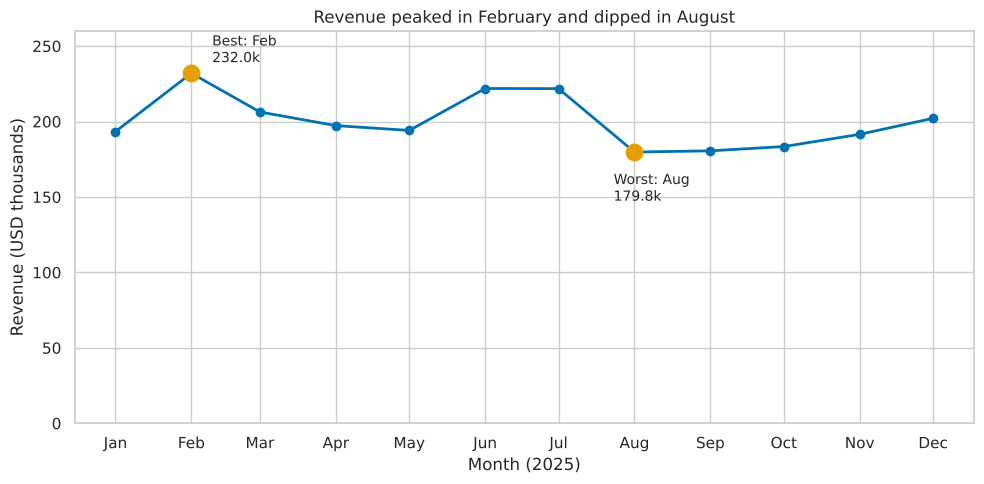

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
x = monthly.index.to_timestamp()
ax.plot(x, monthly.values / 1000, marker="o", color=BLUE, linewidth=2)

best, worst = monthly.idxmax(), monthly.idxmin()
ax.scatter(best.to_timestamp(), monthly[best] / 1000, s=140, color=ORANGE, zorder=5)
ax.annotate(f"Best: {best.strftime('%b')}\n{monthly[best]/1000:.1f}k", (best.to_timestamp(), monthly[best] / 1000),
            textcoords="offset points", xytext=(15, 8), fontsize=10)
ax.scatter(worst.to_timestamp(), monthly[worst] / 1000, s=140, color=ORANGE, zorder=5)
ax.annotate(f"Worst: {worst.strftime('%b')}\n{monthly[worst]/1000:.1f}k", (worst.to_timestamp(), monthly[worst] / 1000),
            textcoords="offset points", xytext=(-15, -35), fontsize=10)

ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set(title="Revenue peaked in February and dipped in August",
       xlabel="Month (2025)", ylabel="Revenue (USD thousands)")
ax.set_ylim(0, 260)
plt.tight_layout()
plt.savefig("monthly_trend.png", dpi=150)
plt.show()

**Takeaway:** Monthly revenue ranged from about USD 180k (August) to USD 232k (February). February was the best month and August the worst.

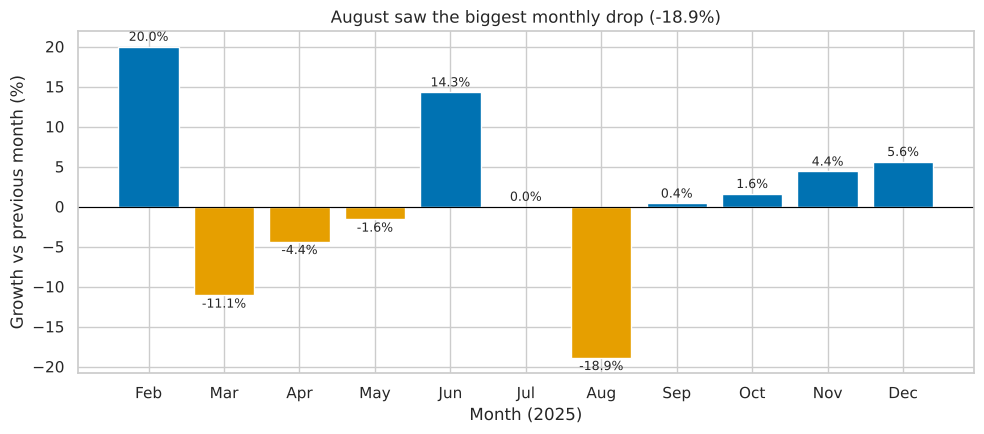

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.5))
g = growth.dropna()
colors = [BLUE if v >= 0 else ORANGE for v in g.values]
ax.bar([p.strftime("%b") for p in g.index], g.values, color=colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="August saw the biggest monthly drop (-18.9%)",
       xlabel="Month (2025)", ylabel="Growth vs previous month (%)")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=2, fontsize=9)
plt.tight_layout()
plt.savefig("monthly_growth.png", dpi=150)
plt.show()

**Takeaway:** Growth jumped +20.0% in February and +14.3% in June, then fell -18.9% in August. Blue bars are growth and orange bars are declines.

In [8]:
quarterly = orders.groupby("quarter")["amount"].sum()
halves = orders.groupby("half")["amount"].sum()
print((quarterly.round(0)).to_string())
print()
print(halves.round(0).to_string())
h1, h2 = halves["H1 (Jan-Jun)"], halves["H2 (Jul-Dec)"]
print(f"\nH2 vs H1 change: {(h2 / h1 - 1) * 100:.1f}%")
print(f"Q4 vs Q1 change: {(quarterly.iloc[3] / quarterly.iloc[0] - 1) * 100:.1f}%")

quarter
2025Q1    631696.0
2025Q2    613291.0
2025Q3    582168.0
2025Q4    577079.0
Freq: Q-DEC

half
H1 (Jan-Jun)    1244987.0
H2 (Jul-Dec)    1159247.0

H2 vs H1 change: -6.9%
Q4 vs Q1 change: -8.6%


**Takeaway:** Revenue fell from about USD 632k in Q1 to USD 577k in Q4 (-8.6%). The second half of the year earned about 6.9% less than the first half (USD 1.16 million vs USD 1.24 million).

### Revenue by weekday

In [9]:
order_days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_day = orders.groupby("weekday")["amount"].agg(["sum", "count"]).reindex(order_days).round(0)
by_day.columns = ["revenue_usd", "orders"]
by_day

,revenue_usd,orders
weekday,,
Monday,370097.0,305
Tuesday,335978.0,283
Wednesday,363020.0,280
Thursday,303746.0,261
Friday,349386.0,290
Saturday,352098.0,290
Sunday,329908.0,291


**Takeaway:** Monday (about USD 370k) and Wednesday (USD 363k) bring the most revenue, and Thursday the least (USD 304k, 261 orders). The weekday gap is modest.

## 6. Compare Categories
I use `groupby` for the total, average and count of orders per category, and a **pivot table** for month by category.

In [10]:
by_category = orders.groupby("category")["amount"].agg(["sum", "mean", "count"]).sort_values("sum", ascending=False)
by_category["share_%"] = (by_category["sum"] / by_category["sum"].sum() * 100)
by_category = by_category.round(1)
by_category

,sum,mean,count,share_%
category,,,,
Fashion,853984.9,1220.0,700,35.5
Electronics,722645.5,1163.7,621,30.1
Home,464114.7,1218.1,381,19.3
Books,363488.2,1219.8,298,15.1


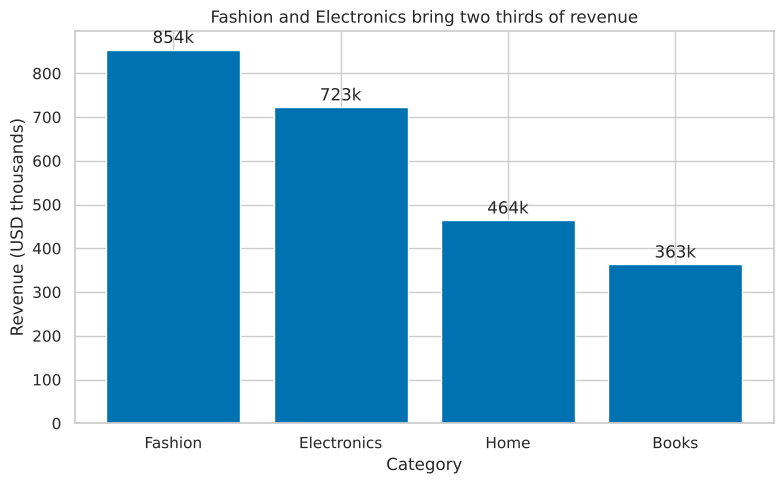

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
cat = by_category.sort_values("sum", ascending=False)
ax.bar(cat.index, cat["sum"] / 1000, color=BLUE)
ax.set(title="Fashion and Electronics bring two thirds of revenue",
       xlabel="Category", ylabel="Revenue (USD thousands)")
ax.bar_label(ax.containers[0], fmt="%.0fk", padding=2)
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.savefig("category_revenue.png", dpi=150)
plt.show()

**Takeaway:** Fashion (USD 854k, 35.5%) and Electronics (USD 723k, 30.1%) together bring about **65.6%** of revenue. The average order value is almost the same in every category (about USD 1,160 to USD 1,220), so the differences come from **how many orders** each category gets (Fashion 700 vs Books 298), not how big each order is.

In [12]:
pivot = pd.pivot_table(orders, values="amount", index="month", columns="category", aggfunc="sum").round(0)
pivot.index = pivot.index.astype(str)
pivot

category,Books,Electronics,Fashion,Home
month,,,,
2025-01,29187.0,62842.0,64666.0,36647.0
2025-02,34034.0,53565.0,86123.0,58305.0
2025-03,27844.0,58056.0,75139.0,45289.0
2025-04,26594.0,83336.0,57058.0,30323.0
2025-05,34426.0,57219.0,68570.0,33876.0
2025-06,32937.0,60037.0,85598.0,43318.0
2025-07,35582.0,72650.0,72648.0,40934.0
2025-08,32551.0,56690.0,71252.0,19291.0
2025-09,21825.0,60389.0,60232.0,38125.0


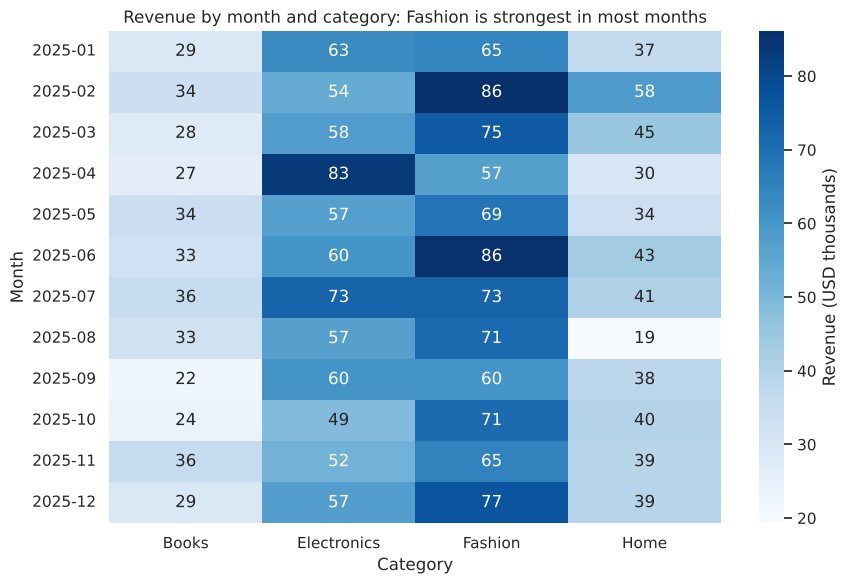

In [13]:
plt.figure(figsize=(9, 6))
sns.heatmap(pivot / 1000, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "Revenue (USD thousands)"})
plt.title("Revenue by month and category: Fashion is strongest in most months")
plt.xlabel("Category")
plt.ylabel("Month")
plt.tight_layout()
plt.savefig("month_category_heatmap.png", dpi=150)
plt.show()

**Takeaway:** Fashion is the top category in 9 of 12 months (Electronics in the other 3), and Books has the lowest total. All four categories earned less in H2 than in H1, and August's dip is mostly **Home**, which fell from about USD 41k in July to USD 19k.

## 7. Find the Best Customers (the 80/20 idea)
The Pareto idea says about 20% of customers bring about 80% of revenue. I test it by asking: **what share of revenue comes from the top 10% of customers?**

In [14]:
spend = orders.groupby("customer_id")["amount"].sum().sort_values(ascending=False)
n_customers = len(spend)
top10_n = n_customers // 10
top20_n = n_customers // 5

top10_share = spend.head(top10_n).sum() / spend.sum()
top20_share = spend.head(top20_n).sum() / spend.sum()
cum_share = spend.cumsum() / spend.sum()
customers_for_80 = int((cum_share < 0.8).sum() + 1)

print(f"Customers: {n_customers}")
print(f"Top 10% ({top10_n} customers) bring {top10_share:.1%} of revenue")
print(f"Top 20% ({top20_n} customers) bring {top20_share:.1%} of revenue")
print(f"Customers needed to reach 80% of revenue: {customers_for_80} of {n_customers} ({customers_for_80 / n_customers:.0%})")
print(f"Average spend per customer: {spend.mean():,.0f} | Median: {spend.median():,.0f}")
spend.head(5).round(0)

Customers: 300
Top 10% (30 customers) bring 18.9% of revenue
Top 20% (60 customers) bring 33.9% of revenue
Customers needed to reach 80% of revenue: 190 of 300 (63%)
Average spend per customer: 8,014 | Median: 7,601


customer_id
226    18140.0
51     18126.0
53     17994.0
131    17639.0
185    17222.0
Name: amount, dtype: float64

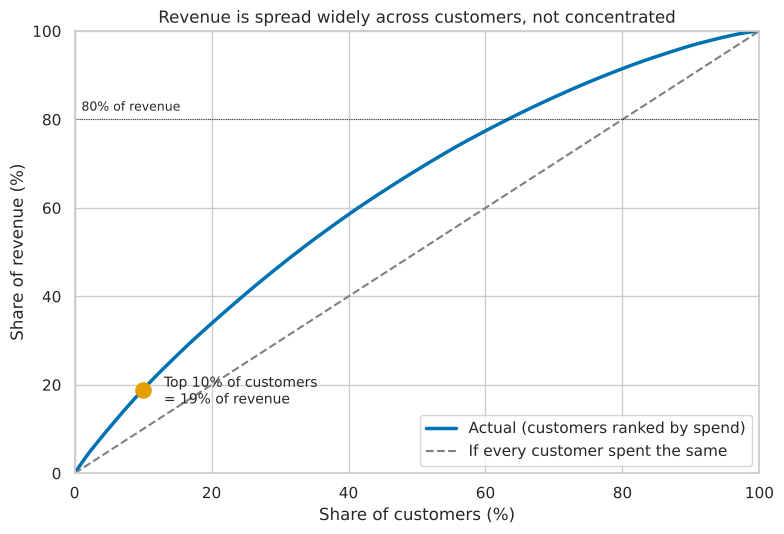

In [15]:
fig, ax = plt.subplots(figsize=(8, 5.5))
pct_customers = np.arange(1, n_customers + 1) / n_customers * 100
ax.plot(pct_customers, cum_share.values * 100, color=BLUE, linewidth=2.5, label="Actual (customers ranked by spend)")
ax.plot([0, 100], [0, 100], color="grey", linestyle="--", label="If every customer spent the same")
ax.scatter([10], [top10_share * 100], s=120, color=ORANGE, zorder=5)
ax.annotate(f"Top 10% of customers\n= {top10_share:.0%} of revenue", (10, top10_share * 100),
            textcoords="offset points", xytext=(15, -10), fontsize=10)
ax.axhline(80, color="black", linewidth=0.6, linestyle=":")
ax.text(1, 82, "80% of revenue", fontsize=9)
ax.set(title="Revenue is spread widely across customers, not concentrated",
       xlabel="Share of customers (%)", ylabel="Share of revenue (%)", xlim=(0, 100), ylim=(0, 100))
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("pareto_customers.png", dpi=150)
plt.show()

**Takeaway:** The 80/20 rule does **not** hold here. The top 10% of customers (30 people) bring only **18.9%** of revenue and the top 20% bring **33.9%**. It takes **190 of 300 customers (63%)** to reach 80% of revenue, so value is spread widely across the customer base.

## 8. Churn Check: Which Customers Are Inactive?
I use a simple rule: a customer with **no order in the last 90 days** is at risk of churning. I also check how often customers come back.

In [16]:
ref_date = orders["order_date"].max()
last_order = orders.groupby("customer_id")["order_date"].max()
days_since = (ref_date - last_order).dt.days
order_counts = orders.groupby("customer_id").size()

inactive = days_since[days_since > 90]
top10_ids = spend.head(top10_n).index
top10_inactive = days_since[top10_ids][days_since[top10_ids] > 90]

print(f"Reference date (last order in data): {ref_date.date()}")
print(f"Customers with 2+ orders : {(order_counts >= 2).mean():.0%}")
print(f"Customers with 5+ orders : {(order_counts >= 5).mean():.0%}")
print(f"Inactive 90+ days        : {len(inactive)} of {n_customers} ({len(inactive) / n_customers:.1%})")
print(f"  ...of which top-10% spenders: {len(top10_inactive)} of {top10_n}")
print(f"Revenue from inactive customers: {spend[inactive.index].sum():,.0f} USD ({spend[inactive.index].sum() / spend.sum():.1%} of total)")

Reference date (last order in data): 2025-12-31
Customers with 2+ orders : 100%
Customers with 5+ orders : 78%
Inactive 90+ days        : 52 of 300 (17.3%)
  ...of which top-10% spenders: 2 of 30
Revenue from inactive customers: 313,652 USD (13.0% of total)


**Takeaway:** Every customer ordered at least twice and 78% ordered five or more times, so the base is loyal. Still, **52 customers (17.3%)** have not ordered in the last 90 days, and only 2 of them are top spenders, so the at-risk group is mostly ordinary customers.

## 9. Recommendations
Each action follows from the numbers above.

**1. Run a campaign to lift the second half of the year (July to October).**
Revenue was about 6.9% lower in H2 than H1, fell from USD 632k in Q1 to USD 577k in Q4, and August was the worst month (USD 180k, -18.9% vs July). A targeted offer in July and August, the months before the dip, would aim to close the gap. Closing even half of the H2 shortfall would be worth about USD 43k.

**2. Grow order volume in Books and Home using cross-selling.**
Average order value is about the same in every category (USD 1,160 to USD 1,220), so the gap between categories is about how many orders each gets (Fashion 700, Home 381, Books 298). Suggesting Books and Home items to Fashion and Electronics buyers could add orders worth about USD 1,200 each.

**3. Use a loyalty programme for all customers and a win-back email for the 52 inactive ones, not a VIP-only scheme.**
The top 10% of customers bring only 18.9% of revenue, and it takes 190 of 300 customers to reach 80%, so a VIP-only offer would reach too little revenue. Instead, reward repeat buying across the whole base, and send a win-back offer to the 52 customers (17.3%) with no order in 90 days, whose past spend totals about USD 314k (13.0% of total revenue).

## 10. Limitations
- **The data is simulated**, so seasonal patterns and the August dip may be random variation, not a real business pattern. Real data is needed to confirm them.
- Only one year of data, so I cannot tell seasonality from a one-off dip.
- The 90-day churn rule is an assumption. Different business types (e.g. weekly groceries vs electronics) would use different windows.
- The analysis shows what happened, not why. The recommendations are suggestions to test, not guaranteed results.

In [17]:
# Check the numbers quoted in the recommendations
print("H2 shortfall vs H1 (USD):", round(h1 - h2))
print("Half of the shortfall (USD):", round((h1 - h2) / 2))
print("Past spend of 52 inactive customers (USD):", round(spend[inactive.index].sum()))

H2 shortfall vs H1 (USD): 85740
Half of the shortfall (USD): 42870
Past spend of 52 inactive customers (USD): 313652
